# 06 · Bayesian Inference with Conjugate Priors

**Covers:** Lab Exercise 6 (call centre, Poisson–Gamma) and Lecture 5 (coin, Beta–Binomial).

### Theory in one cell
$$\underbrace{p(\theta\mid y)}_{\text{posterior}} = \frac{\overbrace{p(y\mid\theta)}^{\text{likelihood}}\ \overbrace{p(\theta)}^{\text{prior}}}{p(y)} \ \propto\ p(y\mid\theta)\,p(\theta)$$

A prior is **conjugate** when the posterior belongs to the same family as the prior:

| Likelihood | Prior | Posterior |
|---|---|---|
| y successes in N trials, Binomial(N, θ) | Beta(a, b) | **Beta(a + y, b + N − y)** |
| $x_1,\dots,x_n$ i.i.d. Poisson(λ) | Gamma(α, β) | **Gamma(α + Σxᵢ, β + n)** |

- Point estimates: **MLE** (data only), **MAP** = mode of the posterior, **posterior mean**.
- **HDI** (highest density interval): the *narrowest* interval containing e.g. 94 % of the posterior mass.
  For a skewed posterior it differs from the equal-tailed interval.

In [1]:
%pip install -q scipy arviz matplotlib

Note: you may need to restart the kernel to use updated packages.


In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats, optimize
from pathlib import Path
import arviz as az                     # HDI (and plot_posterior in ArviZ 0.x, the Colab version)

FIG = Path("figures")
FIG.mkdir(exist_ok=True)


def hdi_from_samples(samples, prob=0.94):
    """HDI that works with both ArviZ 0.x (Colab: hdi_prob=) and ArviZ 1.x (prob=)."""
    try:
        return np.asarray(az.hdi(samples, hdi_prob=prob))
    except TypeError:
        return np.asarray(az.hdi(samples, prob=prob))

## Exercise 1 · Calls per hour (Lab 6)

180 calls in n = 10 hours. Model: calls in each hour $X_i\mid\lambda \sim \text{Poisson}(\lambda)$.

**Derivation of the posterior.**
Likelihood: $L(\lambda) = \prod_i e^{-\lambda}\lambda^{x_i}/x_i! \ \propto\ \lambda^{\sum x_i} e^{-n\lambda}$.
Prior Gamma(α, β): $p(\lambda)\propto \lambda^{\alpha-1}e^{-\beta\lambda}$. Multiplying:

$$p(\lambda\mid x) \propto \lambda^{\alpha+\sum x_i-1}e^{-(\beta+n)\lambda}\ \Rightarrow\ \lambda\mid x\sim\text{Gamma}(\alpha+180,\ \beta+10)$$

**How to choose α and β?** They encode what we know *before* the data: the prior mean is α/β
and β acts like "number of hours already observed". With little prior knowledge use a **weak**
prior, e.g. α = 2, β = 0.1 (mean 20 calls/h, worth only 0.1 hours of data). A strong prior such
as Gamma(200, 10) (= 10 hours with mean 20) would pull the posterior towards 20.

With α = 2, β = 0.1: posterior **Gamma(182, 10.1)**, mode $(182-1)/10.1 \approx 17.92$, mean $182/10.1\approx18.02$.

In [3]:
total_calls, hours = 180, 10
alpha0, beta0 = 2, 0.1                                  # weak prior, mean 20 calls/hour

alpha_post = alpha0 + total_calls                      # conjugate update
beta_post = beta0 + hours

# scipy parametrises the Gamma with scale = 1 / rate  (rate = beta)!
prior = stats.gamma(a=alpha0, scale=1 / beta0)
posterior = stats.gamma(a=alpha_post, scale=1 / beta_post)

mode = (alpha_post - 1) / beta_post                    # most probable value of lambda
print(f"Posterior: Gamma({alpha_post}, {beta_post})")
print(f"mode (MAP) = {mode:.4f}   mean = {posterior.mean():.4f}   sd = {posterior.std():.4f}")

Posterior: Gamma(182, 10.1)
mode (MAP) = 17.9208   mean = 18.0198   sd = 1.3357


In [4]:
# 94 % HDI, computed in two ways
# (1) exactly: among all intervals [lo, F^-1(F(lo) + 0.94)] choose the narrowest
width = lambda lo: posterior.ppf(posterior.cdf(lo) + 0.94) - lo
lo = optimize.minimize_scalar(width, bounds=(posterior.ppf(1e-9), posterior.ppf(0.06)), method="bounded").x
hi = posterior.ppf(posterior.cdf(lo) + 0.94)
print(f"94% HDI (exact)       = [{lo:.3f}, {hi:.3f}]")

# (2) from posterior samples with ArviZ
samples = posterior.rvs(200_000, random_state=1)
print("94% HDI (ArviZ)       =", np.round(hdi_from_samples(samples), 3))

# Equal-tailed interval (3 % in each tail) for comparison - NOT the same as the HDI
print("94% equal-tailed      =", np.round(posterior.ppf([0.03, 0.97]), 3))

94% HDI (exact)       = [15.530, 20.545]
94% HDI (ArviZ)       = [15.518 20.519]
94% equal-tailed      = [15.593 20.614]


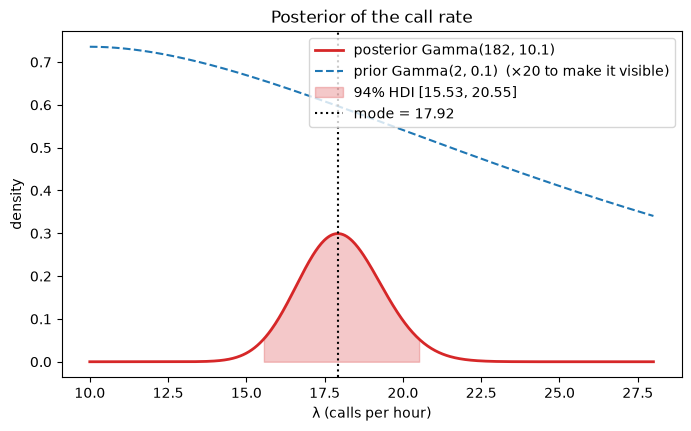

In [5]:
# Plot. On Colab (ArviZ 0.x) the one-liner is:
#   az.plot_posterior(samples, hdi_prob=0.94, point_estimate="mode")
x = np.linspace(10, 28, 600)
plt.figure(figsize=(8, 4.5))
plt.plot(x, posterior.pdf(x), "C3", lw=2, label=f"posterior Gamma({alpha_post}, {beta_post})")
plt.plot(x, prior.pdf(x) * 20, "C0--", label="prior Gamma(2, 0.1)  (×20 to make it visible)")
inside = (x >= lo) & (x <= hi)
plt.fill_between(x[inside], posterior.pdf(x[inside]), alpha=0.25, color="C3", label=f"94% HDI [{lo:.2f}, {hi:.2f}]")
plt.axvline(mode, color="k", ls=":", label=f"mode = {mode:.2f}")
plt.xlabel("λ (calls per hour)")
plt.ylabel("density")
plt.title("Posterior of the call rate")
plt.legend()
plt.savefig(FIG / "06_calls_posterior.png", dpi=150, bbox_inches="tight")
plt.show()

## Exercise 2 · A coin with 8 heads in 10 tosses (Lecture 5)

Likelihood $Y\mid\theta\sim\text{Binomial}(10,\theta)$, prior Beta(a, b) ⇒ posterior Beta(a + 8, b + 2).

$$\text{MLE} = \frac{y}{N},\qquad \text{MAP} = \frac{a+y-1}{a+b+N-2},\qquad E[\theta\mid y] = \frac{a+y}{a+b+N}$$

The stronger the prior (larger a + b), the more the posterior is pulled towards the prior mean.

prior Beta(1,1) -> posterior Beta(9,3):  MLE = 0.800  MAP = 0.800  mean = 0.750
prior Beta(2,2) -> posterior Beta(10,4):  MLE = 0.800  MAP = 0.750  mean = 0.714
prior Beta(20,20) -> posterior Beta(28,22):  MLE = 0.800  MAP = 0.562  mean = 0.560


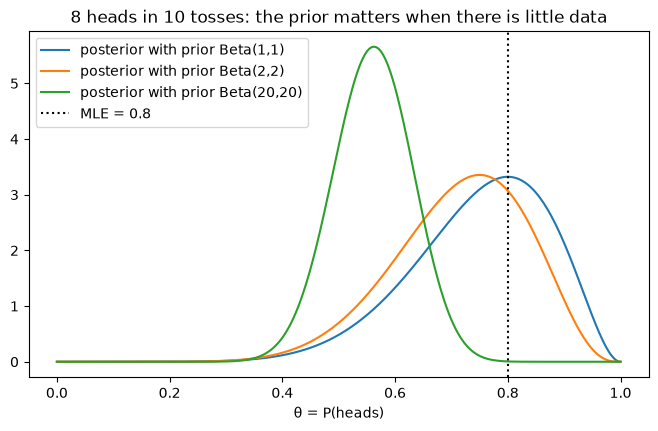

In [6]:
N, y = 10, 8
theta = np.linspace(0, 1, 500)
plt.figure(figsize=(8, 4.5))
for a, b in [(1, 1), (2, 2), (20, 20)]:               # flat, weak and strong priors
    a_post, b_post = a + y, b + N - y
    mle = y / N
    map_ = (a_post - 1) / (a_post + b_post - 2)
    mean = a_post / (a_post + b_post)
    print(f"prior Beta({a},{b}) -> posterior Beta({a_post},{b_post}):  "
          f"MLE = {mle:.3f}  MAP = {map_:.3f}  mean = {mean:.3f}")
    plt.plot(theta, stats.beta.pdf(theta, a_post, b_post), label=f"posterior with prior Beta({a},{b})")
plt.axvline(y / N, color="k", ls=":", label="MLE = 0.8")
plt.xlabel("θ = P(heads)")
plt.title("8 heads in 10 tosses: the prior matters when there is little data")
plt.legend()
plt.savefig(FIG / "06_beta_binomial.png", dpi=150, bbox_inches="tight")
plt.show()

In [7]:
# Posterior predictive: how many heads in 10 NEW tosses? (prior Beta(1,1))
# 1) draw theta from the posterior, 2) draw new data with that theta
rng = np.random.default_rng(0)
thetas = rng.beta(1 + y, 1 + N - y, 50_000)
new_heads = rng.binomial(10, thetas)
pred = np.bincount(new_heads, minlength=11) / len(new_heads)
print("P(k heads in 10 new tosses), k = 0..10:", np.round(pred, 3))
print("P(next toss is heads) = posterior mean =", round((1 + y) / (2 + N), 3))

P(k heads in 10 new tosses), k = 0..10: [0.    0.002 0.006 0.017 0.038 0.077 0.129 0.184 0.217 0.208 0.122]
P(next toss is heads) = posterior mean = 0.75


### Key takeaways
- Write the posterior parameters first; everything else (mode, mean, HDI) follows.
- scipy: `stats.gamma(a=alpha, scale=1/beta)`, `stats.beta(a, b)`.
- HDI ≠ equal-tailed interval for skewed posteriors.